# E0 – Baseline: M0 vs M1, M1b, M2

Same target number of clustered time steps for all methods (150 for the demo models, 144 for SwissX as in the thesis runs).

| ID | Method | Code |
|---|---|---|
| M0 | full horizon (8760 h) | branch code |
| M1 | existing method (`main`) | `d436c9b7` |
| M1b | PR #58 (per-stage re-clustering) | `f69e03d5` |
| M2 | proposed fix (`57-rom-extreme-periods`) | `bd1a0c89` |

Cases:
- **demo**: `examples/clustering_demo`, 1 stage, solved with Gurobi.
- **ms3**: synthetic 2-stage version of the demo (`models/ms3`), solved.
- **swissx**: the 178 SwissX profiles (4 stages), clustered only. Every profile enters as a demand series of a pseudo system, so the clustering sees the same matrix as in the real model if all these profiles are time series there. The model is not solved (needs the wind module and hours of Gurobi time).

Metrics are defined in `scripts/romlab.py` (`series_metrics`, `stage_summary`, `solution_compare`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import romlab as rl

pd.set_option("display.float_format", lambda x: f"{x:,.4g}")
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

def try_run(*args):
    try:
        return rl.run(*args)
    except Exception as exc:  # failed runs are reported, not hidden
        return {"error": str(exc).strip().splitlines()[-1]}

print({k: v for k, v in rl.VARIANTS.items()})

{'M1': 'd436c9b7', 'M1b': 'f69e03d5', 'M2': 'bd1a0c89'}


In [2]:
TARGET = {"demo": 150, "ms3": 150, "swissx": 144}
MODE = {"demo": "rom", "ms3": "rom", "swissx": "cluster"}
VARS = ["M1", "M1b", "M2"]
prof = {c: rl.run(c, "M0", "profiles") for c in TARGET}
full = {c: rl.run(c, "M0", "full") for c in ("demo", "ms3")}
red = {(c, v): try_run(c, v, MODE[c], TARGET[c]) for c in TARGET for v in VARS}
for k, r in red.items():
    print(k, "ERROR: " + r["error"] if "error" in r else f"{r['num_ts']} clustered steps")

('demo', 'M1') 178 clustered steps
('demo', 'M1b') 178 clustered steps
('demo', 'M2') 178 clustered steps
('ms3', 'M1') 178 clustered steps
('ms3', 'M1b') 178 clustered steps
('ms3', 'M2') 178 clustered steps
('swissx', 'M1') 185 clustered steps
('swissx', 'M1b') 185 clustered steps
('swissx', 'M2') 185 clustered steps


## 1. Structure of the clustering per stage

`used` = clustered steps with at least one member hour, `phantom` = steps without members (issue 2), `weight_ne_members` = steps whose weight differs from their number of member hours.

In [3]:
rows = []
for (c, v), r in red.items():
    if "error" in r:
        continue
    df = rl.stage_summary(r, prof[c]["num_horizon_ts"])
    df.insert(0, "variant", v); df.insert(0, "case", c)
    rows.append(df)
structure = pd.concat(rows, ignore_index=True)
structure

,case,variant,stage,num_ts,used,phantom,weight_sum,weight_sum_err,weight_ne_members
0,demo,M1,S1,178,178,0,"8,760",0,0
1,demo,M1b,S1,178,178,0,"8,760",0,0
2,demo,M2,S1,178,178,0,"8,760",0,0
3,ms3,M1,S1,178,178,0,"8,760",0,0
4,ms3,M1,S2,178,178,0,"8,760",0,0
5,ms3,M1b,S1,178,178,0,"8,760",0,0
6,ms3,M1b,S2,178,178,0,"8,760",0,0
7,ms3,M2,S2,178,178,0,"8,760",0,0
8,ms3,M2,S1,178,178,0,"8,760",0,0
9,swissx,M1,S1,185,185,0,"8,760",0,0


## 2. Input-level errors

Absolute values, non-constant series only. `wsum_err`: relative error of the weighted sum; `max_err` / `min_err`: error of the clustered peak / minimum relative to the series range; `dc_nrmse`: duration-curve error; `chr_nrmse`: error of the hourly profile rebuilt from the horizon → cluster map (what the storage balance sees).

In [4]:
met = []
for (c, v), r in red.items():
    if "error" in r:
        continue
    df = rl.series_metrics(prof[c], r)
    df["case"], df["variant"] = c, v
    met.append(df)
met = pd.concat(met, ignore_index=True)
rl.summarize_metrics(met, ["case", "variant"])

wsum_err             max_err             min_err           dc_nrmse chr_nrmse
                    mean       max      mean       max      mean       max     mean      mean
case   variant                                                                               
demo   M1       0.002226  0.009894         0         0 6.438e-10 9.901e-09  0.09021    0.1977
       M1b      0.002226  0.009894         0         0 6.438e-10 9.901e-09  0.09021    0.1977
       M2       5.27e-17  2.04e-16         0         0         0         0  0.09446    0.1986
ms3    M1       0.001272  0.009894   0.08934    0.4126   0.06472    0.2374  0.08346    0.1838
       M1b      0.001624  0.009894 1.406e-07  1.32e-06 7.598e-08  1.24e-06  0.08294    0.1847
       M2      5.049e-17 3.003e-16         0         0         0         0  0.08632    0.1858
swissx M1      0.0006924  0.005627    0.0508    0.5214   0.02315    0.2667  0.02212   0.06354
       M1b      0.001588   0.02768 4.844e-10 3.856e-08 1.088e-09 3.085e-08  0.02258   0.06479
       M2      3.175e-17 2.607e-16         0         0         0         0  0.02414   0.06553

In [5]:
# SwissX by stage and by input file
sx = met[met.case == "swissx"].copy()
sx["file"] = sx.series.str.split("|").str[3].str.split("x").str[0]
display(rl.summarize_metrics(sx, ["variant", "stage"]))

wsum_err             max_err             min_err           dc_nrmse chr_nrmse
                   mean       max      mean       max      mean       max     mean      mean
variant stage                                                                               
M1      S1    8.255e-08 1.055e-06    0.1112    0.5214   0.05885    0.2667  0.02263   0.06321
        S2     0.001532  0.005627 8.743e-18 1.705e-16         0         0  0.02362   0.06752
        S3     0.001207  0.003734 3.855e-18 1.542e-16         0         0  0.02237   0.06379
        S4    6.797e-11 5.345e-10   0.09485    0.3345   0.03528    0.2118  0.01989   0.05962
M1b     S1     0.001751   0.01522 1.988e-09 3.856e-08 4.467e-09 3.085e-08  0.02357   0.06571
        S2     0.001532  0.005627 8.743e-18 1.705e-16         0         0  0.02362   0.06752
        S3     0.001207  0.003734 3.855e-18 1.542e-16         0         0  0.02237   0.06379
        S4     0.001875   0.02768         0         0         0         0  0.02081    0.0622
M2      S1    3.202e-17 1.917e-16         0         0         0         0  0.02494   0.06667
        S2    1.806e-17 1.703e-16         0         0         0         0  0.02535   0.06816
        S3    4.377e-17 2.607e-16         0         0         0         0  0.02395   0.06446
        S4    3.287e-17 1.703e-16         0         0         0         0  0.02233    0.0629

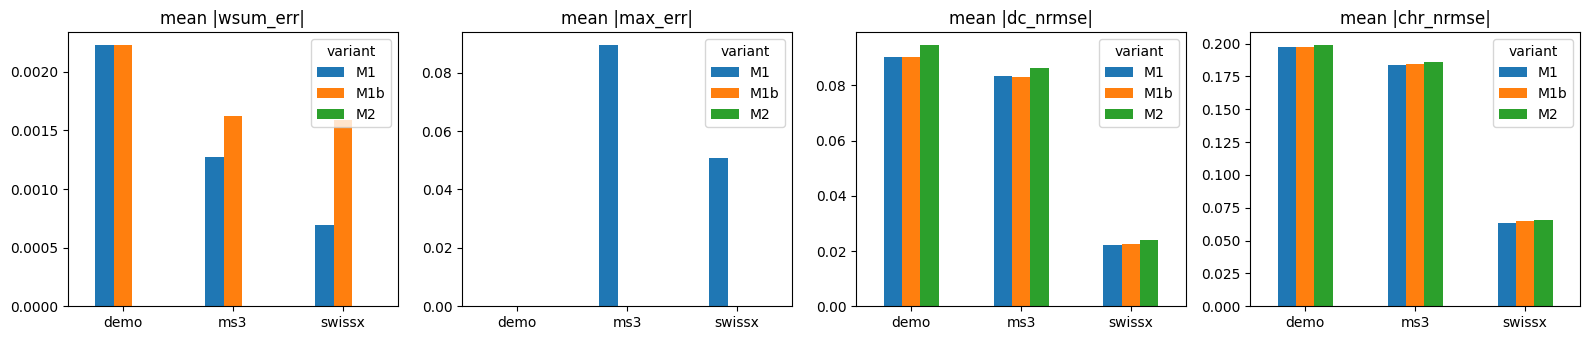

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["wsum_err", "max_err", "dc_nrmse", "chr_nrmse"]):
    d = met[~met.constant].assign(val=lambda x: x[col].abs())
    d.pivot_table(index="case", columns="variant", values="val", aggfunc="mean").plot.bar(ax=ax, rot=0)
    ax.set_title(f"mean |{col}|"); ax.set_xlabel("")
plt.tight_layout()

## 3. Model results (demo, ms3)

In [7]:
cmp = []
for c in ("demo", "ms3"):
    for v in VARS:
        r = red[(c, v)]
        row = {"case": c, "variant": v}
        if "error" in r:
            row["error"] = r["error"]
        else:
            row.update(num_ts=r["num_ts"], **rl.solution_compare(full[c], r))
        cmp.append(row)
pd.DataFrame(cmp)

,case,variant,num_ts,obj_err,cap_abs_diff_rel,techs_flipped,secs_solve
0,demo,M1,178,0.05848,0,0,20.86
1,demo,M1b,178,0.05848,0,0,20.71
2,demo,M2,178,0.05615,0,0,20.94
3,ms3,M1,178,0.06526,0,0,42.42
4,ms3,M1b,178,0.06456,0,0,42.8
5,ms3,M2,178,0.06271,0,0,42.61


In [8]:
for c in ("demo", "ms3"):
    runs = {"M0": full[c], **{v: red[(c, v)] for v in VARS if "error" not in red[(c, v)]}}
    print(f"== {c}: capacities"); display(rl.cap_table(runs))
    ft = rl.flow_table(runs)
    rel = ft.drop(columns="M0").div(ft["M0"].where(ft["M0"].abs() > 1e-9), axis=0) - 1
    print(f"== {c}: weighted import/export/shedding totals, relative to M0"); display(rel)

== demo: capacities


,M0,M1,M1b,M2
"S1,H1,X1",20,20,20,20
"S1,H1,X2",500,500,500,500
"S1,H1,X3",20,20,20,20
"S1,H1,X4",20,20,20,20


== demo: weighted import/export/shedding totals, relative to M0


,M1,M1b,M2
"V_Imp[S1,H1,E1]",2.924e-05,2.924e-05,-0.0006971
"V_Imp[S1,H1,E2]",0.009129,0.009129,0.01103
"V_Imp[S1,H1,E5]",0.002629,0.002629,-2.998e-15
"V_Imp[S1,H1,E6]",-0.002808,-0.002808,1.332e-15
"V_Imp[S1,H2,E1]",-0.0003083,-0.0003083,-1.887e-15
"V_LoadShedding[S1,H1,E1]",0.0292,0.0292,0.03588


== ms3: capacities


,M0,M1,M1b,M2
"S1,H1,X1",20,20,20,20
"S1,H1,X2",500,500,500,500
"S1,H1,X3",20,20,20,20
"S1,H1,X4",20,20,20,20
"S2,H1,X1",20,20,20,20
"S2,H1,X2",500,500,500,500
"S2,H1,X3",20,20,20,20


== ms3: weighted import/export/shedding totals, relative to M0


,M1,M1b,M2
"V_Imp[S1,H1,E1]",2.924e-05,2.924e-05,-0.0006971
"V_Imp[S1,H1,E2]",0.009129,0.009129,0.01103
"V_Imp[S1,H1,E5]",0.002629,0.002629,-2.998e-15
"V_Imp[S1,H1,E6]",-0.002808,-0.002808,1.332e-15
"V_Imp[S1,H2,E1]",-0.0003083,-0.0003083,-1.887e-15
"V_Imp[S2,H1,E1]",-0.0003562,-0.000589,-0.0003741
"V_Imp[S2,H1,E2]",0.01011,0.008722,0.01065
"V_Imp[S2,H1,E3]",-1,-1,-1
"V_Imp[S2,H1,E5]",0.0003451,-0.001724,0.0003451
"V_Imp[S2,H2,E1]",-3.193e-08,5.737e-05,-3.553e-15


## Findings (E0)

**Structure.** At these targets all three methods give the same number of
clustered steps (178 for demo/ms3, 185 for SwissX), every step has members,
and all weights sum to 8760. The phantom steps of issue 2 do not occur with
these data; they need near-identical extreme hours (see the unit test).

**Totals.** Only M2 keeps the weighted sum of every series exact (≤ 3e-16).
M1 and M1b have mean errors of 0.07–0.2 % and maxima of 1 % (demo/ms3) and
up to **2.8 %** (M1b, SwissX S4).

**Peaks.** M1 (`main`) loses the extremes of all stages but one in multi-stage
models: in ms3 the clustered peak is up to 41 % of the range below the true
peak, in SwissX up to 52 % (stages S1 and S4). M1b fixes this (errors ≤ 1e-6,
from tsam's rounding), M2 keeps peaks and minima exactly. Single stage (demo):
all methods keep the peaks.

**Shape.** The duration-curve error (`dc_nrmse`) and the error of the rebuilt
hourly profile (`chr_nrmse`) are about 3–9 % *higher* for M2 than for M1. M1
pulls near-peak hours into the extreme clusters, which shapes the high end of
the duration curve better but biases the totals; M2 keeps totals exact and
puts these hours in regular clusters. See E1: the gap closes as K grows.

**Model results (demo, ms3).** Cost objective vs full horizon: demo +5.8 %
(M1, M1b) → +5.6 % (M2); ms3 +6.5 % (M1) / +6.5 % (M1b) → +6.3 % (M2).
Demand-driven imports match the full model exactly with M2 (E5, E6, H2-E1),
while M1 is off by 0.3 %. Load shedding is 3–4 % too high and the E2 import
1 % too high with all methods. Note: all capacities in demo/ms3 are fixed
(identical in every run), so these models cannot show design differences — we
need a model with free capacities for that.

**Main point.** The differences *between* methods (≤ 0.3 percentage points
of objective) are much smaller than the error that all of them share
(≈ 6 %). The remaining error is not caused by the details of the clustering
fixed in #57; see E1.
